# Question 10 · Particle Swarm Optimization
## Application: minimizing the Rosenbrock function
Implement **PSO** to minimize the two-variable Rosenbrock function, then judge how its parameters affect accuracy, reliability, and search effort.

Each particle represents a candidate pair (x, y). The swarm searches without using derivatives. This is a continuous numerical optimization benchmark, rather than a real-world dataset application.

Run from top to bottom. Dependencies: **NumPy, pandas, Matplotlib**. Explanations are outside code so comments stay minimal.

## 1. Understand the objective
$$f(x,y)=(1-x)^2+100(y-x^2)^2.$$
Both terms are nonnegative and become zero together only at **(1, 1)**. Thus the global minimum is **0**.

The narrow curved valley near y=x² makes progress difficult: getting into the valley is easier than following it to its bottom. We choose a search box **−3 ≤ x ≤ 3, −2 ≤ y ≤ 5**; it contains the known optimum. These bounds are an implementation choice, not specified in the question.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

bounds = np.array([[-3.0, 3.0], [-2.0, 5.0]])
lower, upper = bounds[:, 0], bounds[:, 1]
span = upper - lower

def rosenbrock(points):
    points = np.asarray(points, dtype=float)
    x, y = points[..., 0], points[..., 1]
    return (1 - x)**2 + 100 * (y - x**2)**2

print("f(1, 1) =", rosenbrock([1, 1]))
print("f(0, 0) =", rosenbrock([0, 0]))
print("f(-1, 1) =", rosenbrock([-1, 1]))

f(1, 1) = 0.0
f(0, 0) = 1.0
f(-1, 1) = 4.0


## 2. Plot the search landscape
The color shows log₁₀(1 + f), making the narrow valley easier to see. The objective optimized by PSO remains the original f.

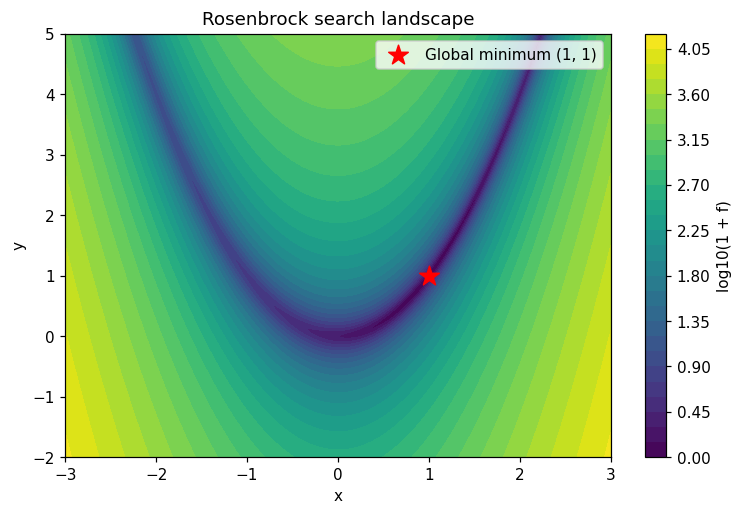

In [2]:
grid_x, grid_y = np.meshgrid(np.linspace(*bounds[0], 250), np.linspace(*bounds[1], 250))
grid_points = np.stack([grid_x, grid_y], axis=-1)
landscape = np.log10(1 + rosenbrock(grid_points))

fig, ax = plt.subplots(figsize=(8, 5))
contours = ax.contourf(grid_x, grid_y, landscape, levels=35, cmap="viridis")
ax.scatter(1, 1, marker="*", s=180, color="red", label="Global minimum (1, 1)")
ax.set(xlabel="x", ylabel="y", title="Rosenbrock search landscape")
fig.colorbar(contours, ax=ax, label="log10(1 + f)")
ax.legend()
plt.show()

## 3. Understand the PSO update
For particle i, position is zᵢ=(xᵢ,yᵢ) and velocity is vᵢ.
$$v_i^{t+1}=w v_i^t+c_1 r_1\odot(p_i-z_i^t)+c_2 r_2\odot(g-z_i^t)$$
$$z_i^{t+1}=z_i^t+v_i^{t+1}.$$
Here ⊙ means componentwise multiplication. Random values are drawn independently for every particle and coordinate at each iteration.

| Symbol | Meaning |
|---|---|
| w | Inertia: retains previous velocity |
| c1 | Cognitive coefficient: attraction toward personal best pᵢ |
| c2 | Social coefficient: attraction toward global best g |
| r1, r2 | Random numbers from Uniform(0,1) |
| pᵢ | Best position particle i has found |
| g | Best position found by the whole swarm |

This notebook uses **synchronous global-best PSO**: all particles move using the same global best from the previous iteration.

## 4. Choose baseline parameters
Velocity limit is a fraction of each coordinate's search range. A fraction of 0.2 limits x movement to ±1.2 and y movement to ±1.4 per update.

In [3]:
baseline = dict(w=0.7, c1=1.5, c2=1.5, n_particles=30,
                n_iterations=200, velocity_fraction=0.2)
success_tolerance = 1e-3
print(baseline)
print("Success means final best f <=", success_tolerance)

{'w': 0.7, 'c1': 1.5, 'c2': 1.5, 'n_particles': 30, 'n_iterations': 200, 'velocity_fraction': 0.2}
Success means final best f <= 0.001


## 5. Initialize positions and velocities
Positions are uniform within the bounds. Initial velocities are small and symmetric around zero. Fix a seed for reproducibility.

In [4]:
rng = np.random.default_rng(42)
n_particles = baseline["n_particles"]
positions = rng.uniform(lower, upper, size=(n_particles, 2))
velocity_limit = baseline["velocity_fraction"] * span
velocities = rng.uniform(-0.1 * span, 0.1 * span, size=(n_particles, 2))
velocities = np.clip(velocities, -velocity_limit, velocity_limit)
initial_positions = positions.copy()
print("First three positions:\n", positions[:3])
print("First three velocities:\n", velocities[:3])

First three positions:
 [[ 1.64373629  1.07214908]
 [ 2.15158752  2.8815762 ]
 [-2.43493591  4.82935646]]
First three velocities:
 [[ 0.20208355 -0.04046531]
 [ 0.07828333  0.3709984 ]
 [ 0.16166198  0.07501116]]


## 6. Evaluate particles and initialize personal bests
Initially, each particle has visited only its starting position, so that is its personal best.

In [5]:
fitness = rosenbrock(positions)
personal_best = positions.copy()
personal_best_fitness = fitness.copy()
print("First five fitness values:", fitness[:5])

First five fitness values: [ 266.01309726  306.79008655  132.70122062  110.04025904 1474.32974576]


## 7. Find the initial global best
For minimization, a lower fitness value is better. Copy the position so later updates do not accidentally change the saved best.

In [6]:
best_index = np.argmin(personal_best_fitness)
global_best = personal_best[best_index].copy()
global_best_fitness = float(personal_best_fitness[best_index])
print("Initial global best:", global_best)
print("Initial best fitness:", global_best_fitness)

Initial global best: [-1.63854391  2.68869796]
Initial best fitness: 6.96341305049578


## 8. Calculate the three velocity components
At initialization, the cognitive component is zero because position equals personal best. It can become nonzero after a particle moves.

In [7]:
r1 = rng.random(positions.shape)
r2 = rng.random(positions.shape)
inertia = baseline["w"] * velocities
cognitive = baseline["c1"] * r1 * (personal_best - positions)
social = baseline["c2"] * r2 * (global_best - positions)
new_velocities = inertia + cognitive + social
print("Particle 0 inertia:", inertia[0])
print("Particle 0 cognitive:", cognitive[0])
print("Particle 0 social:", social[0])
print("Particle 0 new velocity:", new_velocities[0])

Particle 0 inertia: [ 0.14145849 -0.02832572]
Particle 0 cognitive: [0. 0.]
Particle 0 social: [-4.38574583  2.16645025]
Particle 0 new velocity: [-4.24428734  2.13812454]


## 9. Limit velocity and move particles
Clip velocity to the chosen limits. If a position leaves the search box, project it onto the boundary and set its velocity to zero **in the clipped coordinate**. This avoids continuing to push outside the box.

In [8]:
velocities = np.clip(new_velocities, -velocity_limit, velocity_limit)
proposed_positions = positions + velocities
outside = (proposed_positions < lower) | (proposed_positions > upper)
positions = np.clip(proposed_positions, lower, upper)
velocities[outside] = 0
print("Updated first three positions:")
print(positions[:3])

Updated first three positions:
[[ 0.44373629  2.47214908]
 [ 0.95158752  3.04987132]
 [-1.39953573  3.42935646]]


## 10. Update personal bests
Replace a saved personal best only if the new position has lower objective value.

In [9]:
fitness = rosenbrock(positions)
improved = fitness < personal_best_fitness
personal_best[improved] = positions[improved]
personal_best_fitness[improved] = fitness[improved]
print("Particles improving their personal best:", improved.sum())

Particles improving their personal best: 13


## 11. Update the global best
The saved global best can improve or stay equal; it should never worsen.

In [10]:
best_index = np.argmin(personal_best_fitness)
global_best = personal_best[best_index].copy()
global_best_fitness = float(personal_best_fitness[best_index])
print("Global best after one update:", global_best)
print("Best fitness:", global_best_fitness)

Global best after one update: [-0.10502698 -0.03779482]
Best fitness: 1.4594774107788464


## 12. Put the complete algorithm in one reusable function
This restarts initialization, then repeats Steps 8–11. Record the initial state at iteration 0 and every update afterward.

No early stopping is used, so all settings receive their stated budgets. The first time f≤0.001 is recorded only as an evaluation metric. Each full swarm evaluation costs n_particles objective calls; total calls are n_particles × (iterations + 1).

In [11]:
def run_pso(w=0.7, c1=1.5, c2=1.5, n_particles=30,
            n_iterations=200, velocity_fraction=0.2, seed=42):
    rng = np.random.default_rng(seed)
    limit = velocity_fraction * span
    position = rng.uniform(lower, upper, size=(n_particles, 2))
    velocity = rng.uniform(-0.1 * span, 0.1 * span, size=(n_particles, 2))
    velocity = np.clip(velocity, -limit, limit)
    pbest = position.copy()
    pbest_value = rosenbrock(position)
    index = np.argmin(pbest_value)
    gbest, best_value = pbest[index].copy(), float(pbest_value[index])
    history, best_path = [best_value], [gbest.copy()]
    snapshots = [position.copy()]
    first_hit = 0 if best_value <= success_tolerance else np.nan

    for iteration in range(1, n_iterations + 1):
        r1, r2 = rng.random(position.shape), rng.random(position.shape)
        velocity = w * velocity + c1 * r1 * (pbest - position) + c2 * r2 * (gbest - position)
        velocity = np.clip(velocity, -limit, limit)
        proposed = position + velocity
        outside = (proposed < lower) | (proposed > upper)
        position = np.clip(proposed, lower, upper)
        velocity[outside] = 0
        values = rosenbrock(position)
        improved = values < pbest_value
        pbest[improved], pbest_value[improved] = position[improved], values[improved]
        index = np.argmin(pbest_value)
        gbest, best_value = pbest[index].copy(), float(pbest_value[index])
        history.append(best_value)
        best_path.append(gbest.copy())
        snapshots.append(position.copy())
        if np.isnan(first_hit) and best_value <= success_tolerance:
            first_hit = iteration

    return dict(position=gbest, fitness=best_value, history=np.array(history),
                best_path=np.array(best_path), snapshots=np.array(snapshots),
                coordinate_error=float(np.linalg.norm(gbest - [1, 1])),
                first_hit=first_hit, evaluations=n_particles * (n_iterations + 1),
                first_hit_evaluations=n_particles * (first_hit + 1) if np.isfinite(first_hit) else np.nan)

## 13. Run the complete optimization
The fitness threshold measures objective accuracy; the distance to (1,1) separately measures coordinate accuracy.

In [12]:
solution = run_pso(**baseline, seed=42)
print("Best (x, y):", solution["position"])
print(f"Best f: {solution['fitness']:.8e}")
print(f"Distance to (1, 1): {solution['coordinate_error']:.6e}")
print("Success:", solution["fitness"] <= success_tolerance)
print("Objective evaluations:", solution["evaluations"])

Best (x, y): [1.00001762 1.00003425]
Best f: 4.08069887e-10
Distance to (1, 1): 3.851359e-05
Success: True
Objective evaluations: 6030


## 14. Plot convergence and the best-position path
A logarithmic fitness axis makes small improvements visible. The path shows successive global-best positions, not the trajectory of one particle.

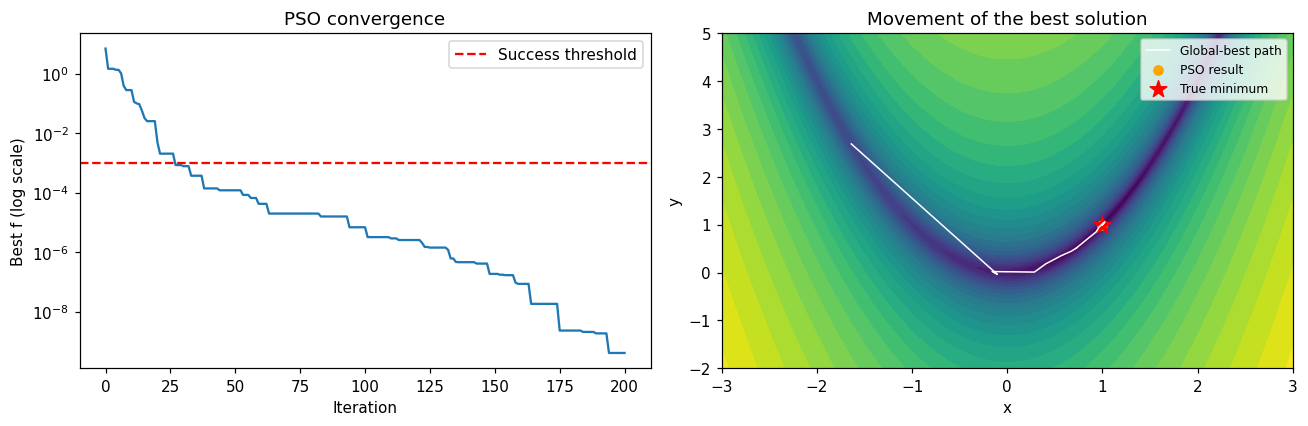

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(np.maximum(solution["history"], 1e-16))
axes[0].axhline(success_tolerance, linestyle="--", color="red", label="Success threshold")
axes[0].set(xlabel="Iteration", ylabel="Best f (log scale)", title="PSO convergence")
axes[0].legend()
axes[1].contourf(grid_x, grid_y, landscape, levels=30, cmap="viridis")
path = solution["best_path"]
axes[1].plot(path[:, 0], path[:, 1], color="white", linewidth=1, label="Global-best path")
axes[1].scatter(*solution["position"], color="orange", label="PSO result")
axes[1].scatter(1, 1, marker="*", s=130, color="red", label="True minimum")
axes[1].set(xlabel="x", ylabel="y", title="Movement of the best solution")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 15. Inspect how the swarm changes
Particles need not all converge to the same position for the saved best to be accurate.

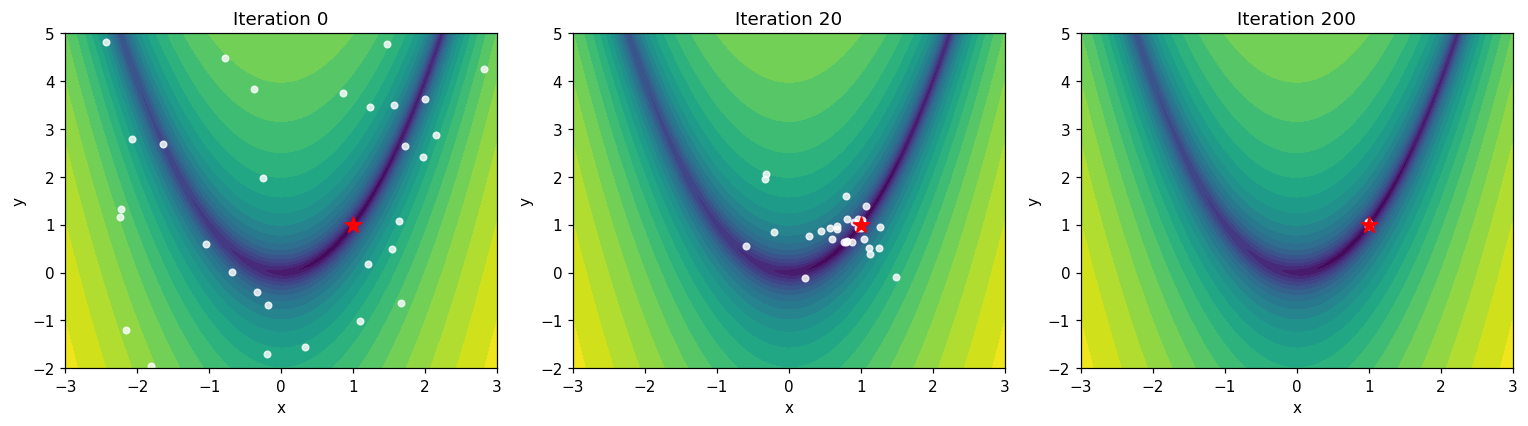

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, iteration in zip(axes, [0, 20, baseline["n_iterations"]]):
    ax.contourf(grid_x, grid_y, landscape, levels=25, cmap="viridis")
    swarm = solution["snapshots"][iteration]
    ax.scatter(swarm[:, 0], swarm[:, 1], s=18, color="white", alpha=0.8)
    ax.scatter(1, 1, color="red", marker="*", s=120)
    ax.set(title=f"Iteration {iteration}", xlabel="x", ylabel="y")
plt.tight_layout()
plt.show()

# Parameter modification and interpretation
## 16. Decide what to change
Change one parameter at a time, holding the others fixed. Use the same 30 seed numbers for each setting. For a fixed swarm size, this preserves the same initial particles across settings.

| Parameter | Tested values | Expected mechanism, not a guaranteed outcome |
|---|---|---|
| w | 0, 0.4, 0.9, 1.2 | More momentum can broaden exploration but cause oscillation |
| c1 | 0, 0.5, 3 | Stronger attraction to each particle's own experience |
| c2 | 0, 0.5, 3 | Stronger attraction to the swarm's best experience |
| n_particles | 10, 60 | More candidates per iteration, but more evaluations |
| n_iterations | 30, 500 | Longer search, but more evaluations |
| velocity_fraction | 0.02, 0.8 | Smaller steps improve control but can slow movement |

Zero coefficients isolate a component's role. Parameter effects interact, so this study does not identify a universal best configuration.

In [15]:
parameter_values = {
    "w": [0, 0.4, 0.9, 1.2],
    "c1": [0, 0.5, 3],
    "c2": [0, 0.5, 3],
    "n_particles": [10, 60],
    "n_iterations": [30, 500],
    "velocity_fraction": [0.02, 0.8]
}
seeds = range(30)
experiments = [("baseline", "—", baseline.copy())]
for parameter, values in parameter_values.items():
    for value in values:
        experiments.append((parameter, value, {**baseline, parameter: value}))
print(f"{len(experiments)} settings × {len(seeds)} seeds")

17 settings × 30 seeds


## 17. Run all experiments
Report mean, median, standard deviation, worst fitness, success rate, and coordinate error. Smaller objective values are better.

First-hit effort is averaged **only over successful runs** and counts completed swarm batches. Failures are excluded from that average, so always read it alongside success rate. Evaluation counts are a work measure, not wall-clock timing.

In [16]:
records, histories = [], {}
for parameter, value, settings in experiments:
    runs = [run_pso(**settings, seed=seed) for seed in seeds]
    final_fitness = np.array([run["fitness"] for run in runs])
    successful = [run for run in runs if run["fitness"] <= success_tolerance]
    label = "Baseline" if parameter == "baseline" else f"{parameter}={value}"
    histories[label] = np.array([run["history"] for run in runs])
    records.append({
        "Parameter": parameter, "Value": value,
        "Mean f": final_fitness.mean(), "Median f": np.median(final_fitness),
        "SD f": final_fitness.std(ddof=1), "Worst f": final_fitness.max(),
        "Mean coordinate error": np.mean([run["coordinate_error"] for run in runs]),
        "Successful runs": len(successful), "Success %": 100 * len(successful) / len(runs),
        "First-hit iteration": np.mean([r["first_hit"] for r in successful]) if successful else np.nan,
        "First-hit evaluations": np.mean([r["first_hit_evaluations"] for r in successful]) if successful else np.nan,
        "Evaluations/run": runs[0]["evaluations"]
    })
results = pd.DataFrame(records)
print("All experiments completed.")

All experiments completed.


## 18. Build the final parameter comparison table
Every interpretation combines **measured change versus baseline** with the parameter's mechanism. Small observed differences across 30 seeds are descriptive, not statistical proof.

Very small objective values are shown in scientific notation rather than rounded to zero. More particles or iterations also change the evaluation budget, so they are not equal-cost comparisons.

In [17]:
mechanisms = {
    "w": "Inertia retains momentum. Too little can stagnate; too much can oscillate even with clipping.",
    "c1": "Cognitive attraction pulls toward personal memory; c1=0 removes it. Excessive attraction can oppose swarm progress.",
    "c2": "Social attraction shares the global best; c2=0 removes it. Strong attraction can collapse diversity early.",
    "n_particles": "More particles provide more candidate coverage and cost more evaluations per iteration.",
    "n_iterations": "More iterations extend the search budget; best-so-far cannot worsen within the same seeded run.",
    "velocity_fraction": "This caps movement relative to the search range. Tight caps slow travel; loose caps allow larger jumps."
}
reference = results.iloc[0]
interpretations = []
for _, row in results.iterrows():
    if row["Parameter"] == "baseline":
        interpretations.append("Reference configuration.")
        continue
    delta = row["Mean f"] - reference["Mean f"]
    success_change = row["Success %"] - reference["Success %"]
    observed = f"Mean f change {delta:+.2e}; success change {success_change:+.1f} percentage points. "
    interpretations.append(observed + mechanisms[row["Parameter"]])
results["Interpretation"] = interpretations
comparison = results[["Parameter", "Value", "Mean f", "Median f", "Worst f", "Success %", "Evaluations/run", "Interpretation"]]
with pd.option_context("display.float_format", "{:.3e}".format, "display.max_colwidth", 180):
    display(comparison)

,Parameter,Value,Mean f,Median f,Worst f,Success %,Evaluations/run,Interpretation
0,baseline,—,1.067e-08,3.203e-10,1.940e-07,1.000e+02,6030,Reference configuration.
1,w,0,5.646e-02,1.696e-03,4.172e-01,5.000e+01,6030,Mean f change +5.65e-02; success change -50.0 percentage points. Inertia retains momentum. Too little can stagnate; too much can oscillate even with clipping.
2,w,4.000e-01,1.267e-08,4.422e-13,3.793e-07,1.000e+02,6030,Mean f change +1.99e-09; success change +0.0 percentage points. Inertia retains momentum. Too little can stagnate; too much can oscillate even with clipping.
3,w,9.000e-01,1.758e-04,5.931e-05,1.143e-03,9.667e+01,6030,Mean f change +1.76e-04; success change -3.3 percentage points. Inertia retains momentum. Too little can stagnate; too much can oscillate even with clipping.
4,w,1.200e+00,5.653e-03,3.916e-03,1.878e-02,1.667e+01,6030,Mean f change +5.65e-03; success change -83.3 percentage points. Inertia retains momentum. Too little can stagnate; too much can oscillate even with clipping.
5,c1,0,3.620e-15,1.525e-19,1.052e-13,1.000e+02,6030,Mean f change -1.07e-08; success change +0.0 percentage points. Cognitive attraction pulls toward personal memory; c1=0 removes it. Excessive attraction can oppose swarm progress.
6,c1,5.000e-01,7.650e-15,9.180e-17,1.380e-13,1.000e+02,6030,Mean f change -1.07e-08; success change +0.0 percentage points. Cognitive attraction pulls toward personal memory; c1=0 removes it. Excessive attraction can oppose swarm progress.
7,c1,3,8.226e-05,4.421e-05,4.200e-04,1.000e+02,6030,Mean f change +8.22e-05; success change +0.0 percentage points. Cognitive attraction pulls toward personal memory; c1=0 removes it. Excessive attraction can oppose swarm progress.
8,c2,0,7.199e-02,1.302e-02,5.160e-01,2.333e+01,6030,Mean f change +7.20e-02; success change -76.7 percentage points. Social attraction shares the global best; c2=0 removes it. Strong attraction can collapse diversity early.
9,c2,5.000e-01,6.898e-09,3.013e-10,1.013e-07,1.000e+02,6030,Mean f change -3.77e-09; success change +0.0 percentage points. Social attraction shares the global best; c2=0 removes it. Strong attraction can collapse diversity early.


## 19. Inspect reliability and speed separately
NaN in first-hit columns means no successful runs. Standard deviation and worst fitness help reveal failures hidden by a good median.

In [18]:
detail = results[["Parameter", "Value", "SD f", "Mean coordinate error", "Successful runs", "First-hit iteration", "First-hit evaluations"]]
with pd.option_context("display.float_format", "{:.3e}".format):
    display(detail)

,Parameter,Value,SD f,Mean coordinate error,Successful runs,First-hit iteration,First-hit evaluations
0,baseline,—,3.657e-08,8.545e-05,30,3.303e+01,1.021e+03
1,w,0,1.086e-01,2.597e-01,15,3.033e+01,9.400e+02
2,w,4.000e-01,6.925e-08,3.837e-05,30,2.873e+01,8.920e+02
3,w,9.000e-01,2.598e-04,1.368e-02,29,6.962e+01,2.119e+03
4,w,1.200e+00,5.183e-03,8.690e-02,5,1.254e+02,3.792e+03
5,c1,0,1.919e-14,2.997e-08,30,2.677e+01,8.330e+02
6,c1,5.000e-01,2.698e-14,6.917e-08,30,2.523e+01,7.870e+02
7,c1,3,1.046e-04,1.382e-02,30,7.527e+01,2.288e+03
8,c2,0,1.233e-01,4.391e-01,7,3.271e+01,1.011e+03
9,c2,5.000e-01,1.956e-08,8.992e-05,30,2.703e+01,8.410e+02


## 20. Compare convergence curves
Curves show the median best fitness across seeds. Their x-axis is iterations; swarm-size settings have different costs per iteration. The dashed line marks the success threshold.

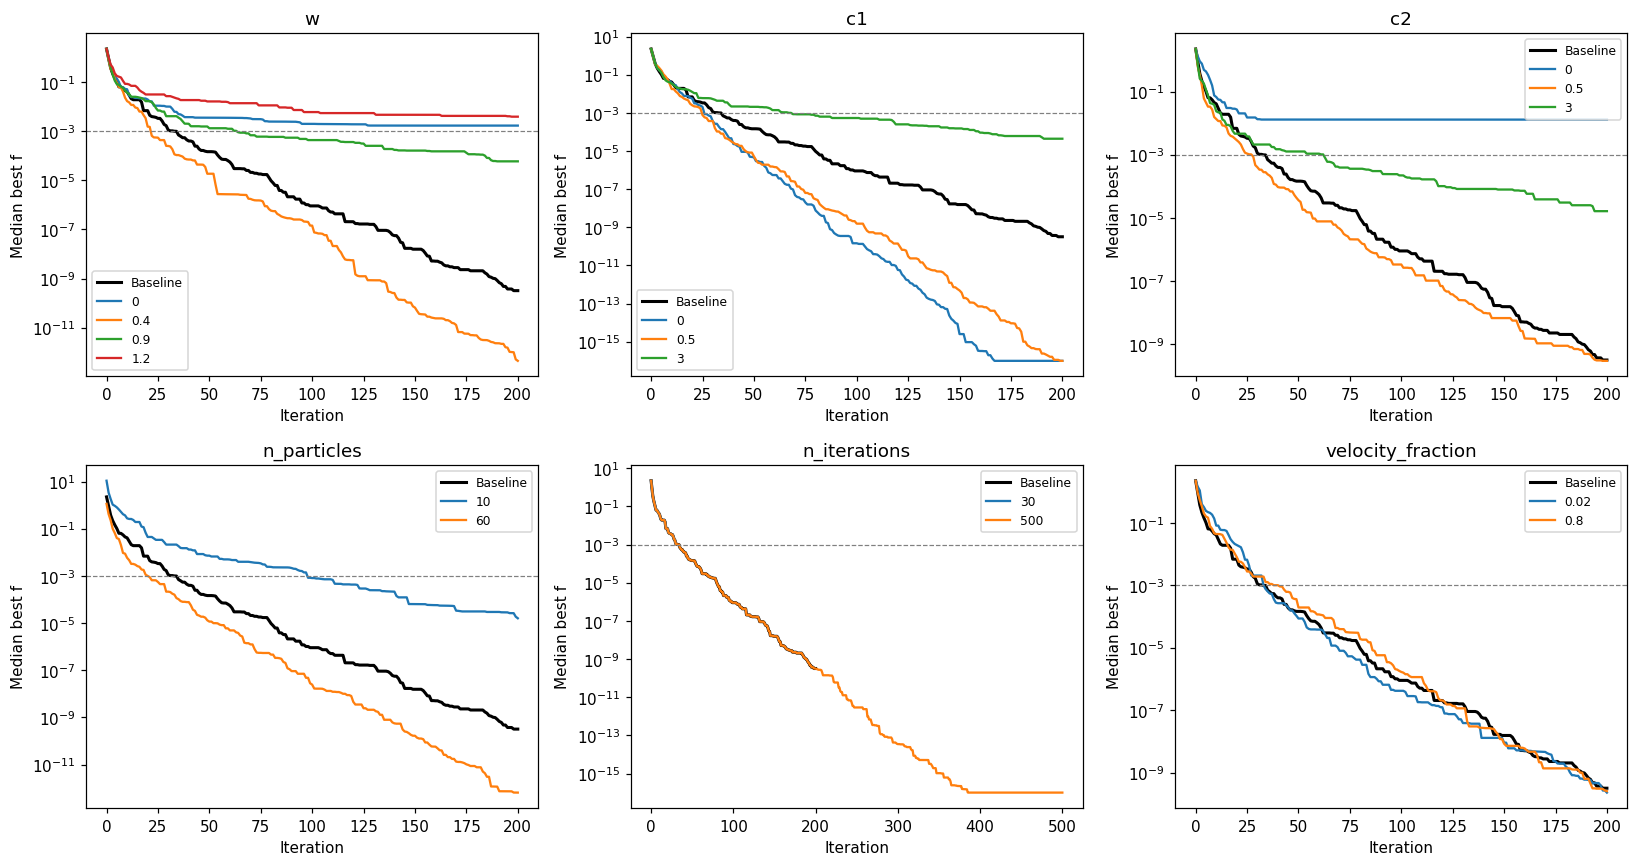

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, parameter in zip(axes.flat, parameter_values):
    history = histories["Baseline"]
    ax.semilogy(np.maximum(np.median(history, axis=0), 1e-16), color="black", linewidth=2, label="Baseline")
    for value in parameter_values[parameter]:
        history = histories[f"{parameter}={value}"]
        ax.semilogy(np.maximum(np.median(history, axis=0), 1e-16), label=str(value))
    ax.axhline(success_tolerance, color="gray", linestyle="--", linewidth=0.8)
    ax.set(title=parameter, xlabel="Iteration", ylabel="Median best f")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 21. A controlled comparison under the same evaluation budget
More particles also cost more work. For a fairer effort comparison, use exactly **6,000 function evaluations** for each setting, including initialization. Iterations = budget / swarm size − 1.

This holds evaluation count constant, not runtime, and it changes the number of opportunities for global-best communication.

In [20]:
evaluation_budget = 6000
budget_records = []
for size in [10, 30, 60]:
    iterations = evaluation_budget // size - 1
    settings = {**baseline, "n_particles":size, "n_iterations":iterations}
    runs = [run_pso(**settings, seed=seed) for seed in seeds]
    budget_records.append({
        "Particles":size, "Iterations":iterations, "Evaluations/run":runs[0]["evaluations"],
        "Mean f":np.mean([r["fitness"] for r in runs]),
        "Success %":100 * np.mean([r["fitness"] <= success_tolerance for r in runs])
    })
budget_results = pd.DataFrame(budget_records)
with pd.option_context("display.float_format", "{:.3e}".format):
    display(budget_results)

,Particles,Iterations,Evaluations/run,Mean f,Success %
0,10,599,6000,9.709e-12,1.000e+02
1,30,199,6000,1.202e-08,1.000e+02
2,60,99,6000,3.924e-07,1.000e+02


## 22. Interpret the actual results
This summary is generated from the experiments rather than assuming that increasing a parameter improves performance. The ranking uses success rate first and mean fitness to break ties; it applies only to these tested settings and budgets.

In [21]:
ranked = results.sort_values(["Success %", "Mean f"], ascending=[False, True])
leader = ranked.iloc[0]
print(f"Baseline: mean f={reference['Mean f']:.3e}; success={reference['Success %']:.1f}%.")
print(f"Top setting by this ranking: {leader['Parameter']}={leader['Value']}; "
      f"mean f={leader['Mean f']:.3e}; success={leader['Success %']:.1f}%.")
for parameter in parameter_values:
    group = results[results["Parameter"] == parameter]
    print(f"{parameter}: success {group['Success %'].min():.1f}%–{group['Success %'].max():.1f}%; "
          f"mean f {group['Mean f'].min():.2e}–{group['Mean f'].max():.2e}.")
print("Consult the equal-budget table before attributing swarm-size gains to better efficiency.")

Baseline: mean f=1.067e-08; success=100.0%.
Top setting by this ranking: n_iterations=500; mean f=1.323e-18; success=100.0%.
w: success 16.7%–100.0%; mean f 1.27e-08–5.65e-02.
c1: success 100.0%–100.0%; mean f 3.62e-15–8.23e-05.
c2: success 23.3%–100.0%; mean f 6.90e-09–7.20e-02.
n_particles: success 93.3%–100.0%; mean f 5.41e-11–5.10e-04.
n_iterations: success 43.3%–100.0%; mean f 1.32e-18–5.56e-03.
velocity_fraction: success 100.0%–100.0%; mean f 3.44e-09–1.86e-08.
Consult the equal-budget table before attributing swarm-size gains to better efficiency.
